In [1]:
import os
%load_ext autoreload
%autoreload 1
%aimport utility.functions
%aimport src.analysis
%aimport src.dataset
%aimport src.plots
%aimport src.simulation
import numpy as np
import utility.functions as fn
import src.simulation as sim
import src.analysis as an
import src.dataset as ds
import src.plots as plots
import torch
from scipy.stats import norm
import pandas as pd
from utility.double_beta_spectrum import pdf_ratio2b
import matplotlib.pyplot as plt
channels = [3, 5, 9, 11, 13, 15, 17, 19]
channel_ID = [5, 9, 11, 10, 4, 2, 12, 3]

Main loop to compute the BI for all channels and acceptance levels

In [ ]:
# Initialize output DataFrame
out_data = pd.DataFrame(columns=["channel_ID", "channel", "acceptance", "BI", "rp","J"])
out_data.to_csv('../outputs/BI_results_interp.csv', index=False)
n_deriv = 0

for index_channel in np.argsort(channel_ID):
    channel = 3#channels[index_channel]
    
    # Load datasets and channel specifications
    data_single, data_pileup, _ = ds.create_data_sets(channel, win_length=2000, shift=0, pos_prefix="_bis")
    #data_single, data_pileup = ds.create_data_sets_denoise(channel, win_length=2000, shift=0, pos_prefix="_bis")
    H_unit, S, nps, w, pulse_factor, dmean = ds.get_channel_specs(channel, n_deriv=n_deriv, window_fct = np.hanning) #, nps_name="denoised_noise"
    
    signal_amp = ds.get_amp_Q_val(channel)*pulse_factor
    t_min, t_max, N_t = 0, 8e-4, 100
    r_min, r_max, N_r = 0., .5, 25
    
    ratio_distribution = pdf_ratio2b(np.linspace(r_min, r_max, N_r))
    ratio_distribution /= np.mean(ratio_distribution)
    
    # Convert data to PyTorch tensors
    S_torch = torch.tensor(S, dtype=torch.cfloat)
    H_unit_torch = torch.tensor(H_unit, dtype=torch.cfloat)
    w_torch = torch.tensor(w, dtype=torch.cfloat)
    t_torch = torch.linspace(t_min, t_max,N_t, dtype=torch.cfloat)
    r_torch = torch.linspace(r_min, r_max, N_r, dtype=torch.cfloat)
    nps_torch = torch.tensor(nps, dtype=torch.cfloat)
    signal_amp_torch = torch.tensor(signal_amp, dtype=torch.float32)
    ratio_distribution_torch = torch.tensor(ratio_distribution, dtype=torch.cfloat)

    # Loop over acceptance levels
    # acceptances = [0.7, 0.8, 0.84, 0.87, 0.9, 0.92, 0.93, 0.94, 0.95, 0.96, 0.99]
    acceptances = [0.9]
    for acceptance in acceptances:
        N_sigma = norm.ppf(1 - (1 - acceptance) * 100 / 100)
        f1_opt, f2_opt = np.load(f"../outputs/Pileup_filter_functions/channel_{channel}/functions_eff{int(acceptance*100):d}_d0.npy")
        # print(torch.tensor(f1_0,dtype=torch.float).size())
        # f1_opt, f2_opt, J_values = an.optimize_filters(S_torch, H_unit_torch, w_torch, t_torch, r_torch, nps_torch, signal_amp_torch,ratio_distribution_torch, N_sigma=N_sigma, n_trials=500, verbose=True)#, f1_init=torch.tensor(f1_0,dtype=torch.float), f2_init=torch.tensor(f2_0,dtype=torch.float))
        # J = J_values[-1]
        #save_filter_function 
        # np.save(f"../outputs/training_Js/channel_{channel}/J_{int(acceptance*100):d}_d0", np.array(J_values))
        # np.save(f"../outputs/Pileup_filter_functions/channel_{channel}/functions_eff{int(acceptance*100):d}_d0", np.array([f1_opt, f2_opt]))
        f1_t, f2_t = torch.tensor(f1_opt,dtype=torch.float32), torch.tensor(f2_opt,dtype=torch.float32)
        
        S_H_delayed, S_H, S2_over_nps = an.precompute_constants(S_torch, H_unit_torch, w_torch, t_torch, nps_torch)
        J = an.compute_J(f1_t, f2_t, S_H_delayed, r_torch, S_H, S2_over_nps, signal_amp_torch, ratio_distribution_torch, N_sigma=N_sigma)
        
        # Compute PSD and BI
        BI, rp, PSD_pileup, PSD_single, Amp_1_pileup, Amp_2_pileup, Amp_1_single, Amp_2_single = an.compute_BI(data_pileup, data_single, acceptance, H_unit, f1_opt, f2_opt,window_fct = np.hanning,n_deriv = n_deriv,full_output = True)
        # sigma_rp, sigma_BI = an.compute_BI_uncertainty(data_pileup, data_single, acceptance, H_unit, f1_opt, f2_opt, n_deriv=n_deriv, n_toys=100)
        # Append results to DataFrame
        # out_data = pd.concat([out_data, pd.DataFrame([{"channel_ID": channel_ID[index_channel], "channel": channel, 
        #                                                "acceptance": acceptance, "BI": BI, "rp": rp, "J": J_values[-1]}])], ignore_index=True)
        # Save results to CSV
        # out_data.to_csv('../outputs/BI_results_interp_d0.csv', index=False)
        print(f"Channel {channel}, Acceptance {acceptance}: J={J}, 1-rp={1-rp}, BI={BI}")
    break


In [ ]:
channel = 9
n_deriv = 0
for channel in channels:
    data_single, data_pileup, _, _, _ = ds.create_data_sets(channel, win_length=2000, shift=0, pos_prefix="_bis")
    H_unit, S, nps, w, pulse_factor = ds.get_channel_specs(channel, n_deriv=n_deriv, window_fct = np.hanning) #, nps_name="denoised_noise"
    acceptance = 0.9
    f1_opt, f2_opt = np.load(f"../outputs/Pileup_filter_functions/channel_{channel}/functions_eff{int(acceptance*100):d}_d0.npy")
    # BI, rp, PSD_pileup, PSD_single, Amp_1_pileup, Amp_2_pileup, Amp_1_single, Amp_2_single = an.compute_BI_torch(data_pileup, data_single, acceptance, torch.tensor(H_unit), torch.tensor(f1_opt), torch.tensor(f2_opt),window_fct = torch.signal.windows.hann,n_deriv = n_deriv,full_output = True)
    # sigma_rp, sigma_BI = an.compute_BI_uncertainty_torch(PSD_single, PSD_pileup, acceptance, rp)
    # print(f"Channel {channel}, Acceptance {acceptance}: 1-rp={1-rp:.3f} +/- {sigma_rp:.3f} , BI={BI*1e5:.2f} +/- {sigma_BI*1e5:.2f} 1e-5 ckky")

    BI, rp, PSD_pileup, PSD_single, Amp_1_pileup, Amp_2_pileup, Amp_1_single, Amp_2_single = an.compute_BI(data_pileup, data_single, acceptance, H_unit, f1_opt, f2_opt,window_fct = np.hanning,n_deriv = n_deriv,full_output = True)
    sigma_rp, sigma_BI = an.compute_BI_uncertainty(PSD_single, PSD_pileup, acceptance, rp)
    
    print(f"Channel {channel}, Acceptance {acceptance}: 1-rp={1-rp:.3f} +/- {sigma_rp:.3f} , BI={BI*1e5:.2f} +/- {sigma_BI*1e5:.2f} 1e-5 ckky")

Comparaison between analytical and simulated PSD for channel 9, acceptance 90%

In [ ]:
from src.plots import plot_biais_vs_dt
import matplotlib.pyplot as plt
S_H_delayed, S_H, S2_over_nps = an.precompute_constants(S_torch, H_unit_torch, w_torch, t_torch, nps_torch)
f1_opt, f2_opt = np.load(f"../outputs/Pileup_filter_functions/channel_{channel}/functions_eff90_V3.npy")
f1,f2  = torch.tensor(f1_opt,dtype=torch.cfloat), torch.tensor(f2_opt,dtype=torch.cfloat)
muY, sigmaY, mu1, mu2, var1, var2, cov12= an.compute_mu_sigma(f1, f2, S_H_delayed,r_torch, S_H, S2_over_nps, signal_amp, return_all=True)
mu = torch.mean(ratio_distribution_torch[:,None]*(1-muY.real), dim = 0).numpy().real
sigma = torch.sqrt(torch.mean(ratio_distribution_torch[:,None]*sigmaY**2, dim = 0)+torch.mean(ratio_distribution_torch[:,None]*(1-muY.real)**2, dim = 0)-mu**2).numpy().real
fig,ax,ax1=plot_biais_vs_dt(PSD_single.real, PSD_pileup.real, dt_pileup,cut=1-cut,bins=20)
ax.fill_between(t_torch.numpy().real*1e3, (mu-sigma).real, (mu+sigma).real, alpha=0.2, color='blue', label='Analytical PSD $\pm$ 1 std')
ax.plot(t_torch.numpy().real*1e3, mu.real, color='blue', label='Analytical PSD mean')
ax.set_xlim(0,0.8)
ax.set_ylim(-0.003,0.015)
ax.legend()
plt.show()

This is a test to study the impact of the Bessel filter cutoff frequency on the filter optimization and on the final BI.

In [ ]:
from src.simulation import bessel_filter_coeffs, filtered_pulse_model, pulse_model
from lmfit import Model
from scipy.signal import freqz

freq = np.fft.rfftfreq(2000, d=1e-4)  # Hz
omega = 2 * np.pi * freq  # rad/s
fs = 1e4
t = np.arange(0,2000)/fs
n_deriv = 0
acceptance = 0.9
N_sigma = norm.ppf(1 - (1 - acceptance) * 100 / 100)

model = Model(filtered_pulse_model,independent_vars=['t'],param_names=['A','t0','tau_rise','tau_decay1','tau_decay2','p'])
params = model.make_params(A=1,t0=0.1, tau_rise=1e-4,tau_decay1=1e-3,tau_decay2=2e-3,p=0.5)

_, h_bessel_small_2500 = freqz(*bessel_filter_coeffs(6, 2500, 1e4), worN=1001)
h_bessel_2500 = np.concatenate([h_bessel_small_2500, np.conj(h_bessel_small_2500[1:1000][::-1])])
for channel in [9]:    
    H_unit, S, nps, w, pulse_factor = ds.get_channel_specs(channel, n_deriv=0, window_fct = np.hanning)
    
    w_torch = torch.tensor(w, dtype=torch.cfloat)
    t_torch = torch.linspace(0, 8e-4, 100, dtype=torch.cfloat)
    r_torch = torch.linspace(0., .5, 25, dtype=torch.cfloat)
    signal_amp = ds.get_amp_Q_val(channel)*pulse_factor
    signal_amp_torch = torch.tensor(signal_amp, dtype=torch.float32)
    ratio_distribution = pdf_ratio2b(r_torch.numpy())
    ratio_distribution /= np.mean(ratio_distribution)
    ratio_distribution_torch = torch.tensor(ratio_distribution, dtype=torch.cfloat)
    nps_torch = torch.tensor(nps, dtype=torch.cfloat)
    
    S_torch = torch.tensor(S, dtype=torch.cfloat)
    H_unit_torch = torch.tensor(H_unit, dtype=torch.cfloat)
    f1_opt, f2_opt, J_values = an.optimize_filters(S_torch, H_unit_torch, w_torch, t_torch, r_torch, nps_torch, signal_amp_torch,ratio_distribution_torch, N_sigma=N_sigma, n_trials=500, verbose=False)
    
    result = model.fit(np.fft.ifft(S),params,t=t, order=6,fc=2500,nan_policy='omit')  
    S_bis = np.fft.fft(filtered_pulse_model(t, **result.params,order=6,fc=2500))
    H_bis = np.conj(S_bis) / nps
    H_unit_bis = H_bis / np.mean(np.abs(H_bis * S_bis))
    
    S_torch = torch.tensor(S_bis, dtype=torch.cfloat)
    nps_torch = torch.tensor(nps, dtype=torch.cfloat)
    H_unit_torch = torch.tensor(H_unit_bis, dtype=torch.cfloat)
    
    f1_opt_bis, f2_opt_bis, J_values_bis = an.optimize_filters(S_torch, H_unit_torch, w_torch, t_torch, r_torch, nps_torch, signal_amp_torch,ratio_distribution_torch, N_sigma=N_sigma, n_trials=500, verbose=False)
    

In [ ]:
fig, ax1 = plt.subplots(figsize=(8,6))
ax1.plot(freq, f1_opt[:1001],c="r",alpha=0.8,label='m1 & m2 with injected pulse')
ax1.plot(freq, f2_opt[:1001],c="r",alpha=0.8)
ax1.plot(freq, f1_opt_bis[:1001],c="b",alpha=0.8,label='m1 & m2 with Fitted pulse')
ax1.plot(freq, f2_opt_bis[:1001],c="b",alpha=0.8)
ax1.set_xscale('log')
ax1.set_yscale('log')
ax1.set_ylabel('Filter Amplitude',fontdict = {'size':14})
ax1.set_xlabel('Frequency (Hz)',fontdict = {'size':14})
ax1.tick_params(axis='both', which='major', labelsize=12)
ax2 = ax1.twinx()
ax2.plot(freq, np.abs(S[:1001]),c="coral",label='Injected Pulse')
ax2.plot(freq, np.abs(S_bis[:1001]),c="dodgerblue",ls='--',label='Fitted Pulse')
ax2.set_xscale('log')
ax2.set_yscale('log')
ax2.set_ylim(1e-4,100)
ax2.set_ylabel('Pulse Amplitude Spectrum', color='k',fontdict = {'size':14})
ax2.tick_params(axis='both', which='major', labelsize=12)

ax1.vlines(freq[np.argwhere(np.abs(h_bessel_2500)<1e-3)[0][0]],0,100,label='1e-3 Bessel reduction',colors='k',linestyles='--')
handles1, labels1 = ax1.get_legend_handles_labels()
handles2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(handles1 + handles2, labels1 + labels2, fontsize=12,loc='lower left')
# ax1.vlines(freq[np.argwhere(np.abs(h_bessel_2500)<1e-3)[0][0]],0,100,label='Cutoff Frequency',colors='k',linestyles='--')
plt.show()

In [ ]:

freq = np.fft.rfftfreq(2000, d=1e-4)  # Hz
omega = 2 * np.pi * freq  # rad/s
fs = 1e4
t = np.arange(0,2000)/fs
n_deriv = 0
acceptance = 0.9
N_sigma = norm.ppf(1 - (1 - acceptance) * 100 / 100)

model = Model(filtered_pulse_model,independent_vars=['t'],param_names=['A','t0','tau_rise','tau_decay1','tau_decay2','p'])
params = model.make_params(A=1,t0=0.1, tau_rise=1e-4,tau_decay1=1e-3,tau_decay2=2e-3,p=0.5)

_, h_bessel_small_2500 = freqz(*bessel_filter_coeffs(6, 2500, 1e4), worN=1001)
h_bessel_2500 = np.concatenate([h_bessel_small_2500, np.conj(h_bessel_small_2500[1:1000][::-1])])
fig,(ax1,ax2) = plt.subplots(2,1, figsize=(10,8), sharex=True, gridspec_kw={'height_ratios': [2, 1],'hspace':0})
for channel in [9]:    
    H_unit, S, nps, w, pulse_factor = ds.get_channel_specs(channel, n_deriv=0, window_fct = np.hanning)
    
    result = model.fit(np.fft.ifft(S),params,t=t, order=6,fc=2500,nan_policy='omit')
    ax1.plot(freq, np.abs(S)[:1001], label='Injected Pulse')
    S_fit = np.fft.rfft(filtered_pulse_model(t,**result.params,order=6,fc=2500))
    ax1.plot(freq, np.abs(S_fit), label='Fitted Pulse in time domain')
    ax1_bis = ax1.twinx()
    ax1_bis.plot(freq, np.abs(nps[:1001]), label='NPS',c="r",alpha=0.5)
    ax1_bis.set_yscale('log')
    ax1_bis.set_ylabel('Noise Power Spectrum', color='r',fontdict = {'size':14})
    ax1_bis.tick_params(axis='y', labelcolor='r', colors='r')
    ax1.set_xscale('log')
    ax1.set_yscale('log')
    ax1.set_ylim(1e-4,100)
    ax1.set_ylabel('Pulse Amplitude Spectrum',fontdict = {'size':14})
    ax1.legend(fontsize=12,loc='lower left')
    ax2.plot(freq, np.abs(S_fit-S[:1001]), label='Fit Residuals',ls="",marker='o',markersize=1)
    ax2.set_xscale('log')
    ax2.set_yscale('log')
    # ax2.set_ylim(0.,0.5)
    ax2.set_xlabel('Frequency (Hz)',fontdict = {'size':14})
    ax2.set_ylabel('Residual Amplitude',fontdict = {'size':14})
    ax2.legend(fontsize=12,loc='lower left')

In [ ]:
import struct
path = "/media/mp274748/Transcend/data/Aquisition_card/000037_20251202T164114_001_000.bin"
data = ds.BinaryDataset(path,win_length = 2000)
nps = an.create_NPS(data)
# pulse = filtered_pulse_model(t=np.arange(2000)/data.samplingRate, **params, order=6,fc=2500,nan_policy='omit')
# S_2500 = np.fft.fft(pulse*np.hanning(2000))
plt.plot(np.fft.rfftfreq(data.win_length,1/data.samplingRate),nps[:data.win_length//2+1])
plt.xscale('log')
plt.yscale('log')

In [ ]:
channels = [3, 5, 9, 11, 13, 15, 17, 19]
fig,axes = plt.subplots(4,2, figsize=(12,16))
for channel in channels:
    ax = axes.flatten()[channels.index(channel)]
    data1 = pd.read_csv(f"../outputs/Systematics/BI_channel_{channel}_varying_window_size_indiv_nps_opt_m.csv")
    data2 = pd.read_csv(f"../outputs/Systematics/BI_channel_{channel}_varying_window_size_indiv_nps_opt_m_2.csv")
    data = pd.concat([data2,data1], ignore_index=True)
    ax.plot(data["window_size"]*1e-1, data["1-rp"], label=f"Channel {channel} indiv nps 1-rp",marker='o')
    ax.plot(data["window_size"]*1e-1, data["J"]+0.03, label=f"Channel {channel} indiv nps J",marker='o')
    ax.axvline(x=500, color='k', linestyle='--', label='injected pulse window size')
    ax.legend()
    ax.set_xlabel("Window Size (ms)")
    ax.set_ylabel("Pileup misidentification rate")
    

In [ ]:
import glob
import os
cmap = plt.get_cmap("coolwarm")
files = glob.glob(os.path.join("../outputs/","**", "functions_eff90_window_**"), recursive = True)
for i,file in enumerate(files):
    channel = int(file.split("channel_")[1].split("/")[0])
    window_size = int(file.split("window_")[1].split(".npy")[0])
    f1_opt, f2_opt = np.load(file)
    plt.plot(np.fft.fftfreq(len(f1_opt),1e-4)[:len(f1_opt)//2],f1_opt[:len(f1_opt)//2], label=f"Channel {channel} window {window_size}",c=cmap(i/len(files)),lw=1,alpha=.5)
    plt.plot(np.fft.fftfreq(len(f2_opt),1e-4)[:len(f2_opt)//2],f2_opt[:len(f2_opt)//2], c=cmap(i/len(files)),lw=1,alpha=.5)
plt.xscale('log')
plt.yscale('log')
plt.ylim(1e-2,2e1)
plt.xlim(2e2,5e3)
plt.legend()

In [ ]:
import glob
import matplotlib as mpl
files = glob.glob(os.path.join("../outputs/","**", "BI_channel_**_varying_grid_size.csv"), recursive = True)
for i,file in enumerate(files):
    df = pd.read_csv(file)
    plt.plot(df["grid_N"], df["1-rp"],marker='o')
    plt.plot(df["grid_N"], df["J"],marker='o')
    plt.show()
files = glob.glob(os.path.join("../outputs/","**", "J_90_N_grid_**.npy"), recursive = True)
cmap = plt.get_cmap("viridis")
grid_Ns = []
for i,file in enumerate(files):
    channel = int(file.split("channel_")[1].split("/")[0])
    grid_N = int(file.split("N_grid_")[1].split(".npy")[0])
    grid_Ns.append(grid_N)
    J_values = np.load(file)
    plt.plot(np.arange(len(J_values)), J_values, label=f"Channel {channel} grid N {grid_N}",c=cmap(i/len(files)))
sm = mpl.cm.ScalarMappable(cmap=cmap, norm=mpl.colors.Normalize(vmin=min(grid_Ns), vmax=max(grid_Ns)))
cbar = plt.colorbar(sm, pad=0.01)
plt.show()
files = glob.glob(os.path.join("../outputs/","**", "functions_eff90_N_grid_**.npy"), recursive = True)
cmap = plt.get_cmap("viridis")
for i,file in enumerate(files):
    channel = int(file.split("channel_")[1].split("/")[0])
    grid_N = int(file.split("N_grid_")[1].split(".npy")[0])
    f1,f2 = np.load(file)
    window_size = len(f1)
    plt.plot(np.fft.fftfreq(window_size,1e-4)[:window_size//2], f1[:window_size//2], label=f"Channel {channel} grid N {grid_N}",c=cmap(i/len(files)),alpha=0.5)
    plt.plot(np.fft.fftfreq(window_size,1e-4)[:window_size//2], f2[:window_size//2], c=cmap(i/len(files)),alpha=0.5)

In [ ]:
from scipy.optimize import curve_fit
from matplotlib.gridspec import GridSpec
meas_name = "000813_20230628T161508"
fig = plt.figure(figsize=(16, 20))
outer_gs = GridSpec(4, 2, figure=fig, hspace=0.3, wspace=0.25)
for i,index_channel in enumerate(np.argsort(channel_ID)):
    channel = channels[index_channel]
    meanpulse = np.fromfile(ds.find_file(f"{meas_name}_{channel:03}_???.bin_edmean.bin",
                                          specific_subdir = "RUN9_pulse_injected_new/"))
    t = np.arange(-len(meanpulse)//2,len(meanpulse)//2)*1e-4
    p0=[1,t[np.argmax(meanpulse)],-1000,-1339.1, -237.0,-100, -1000.0]
    fit_fct_pole = lambda x,*params:  sim.apply_bessel_to_pulse(t,  sim.pulse_pole_zero(x, *params), fc=2500, order=6, fs=1e4)
    popt, pcov = curve_fit(fit_fct_pole, t, meanpulse, p0=p0,bounds=([0,-0.5,-5000,-5000,-5000,-5000,-5000],[10,0.5,0,0,0,0,0]))
    
    meanpulse_fit = fit_fct_pole(t, *popt)
    print(channel,np.sum((meanpulse - meanpulse_fit)**2))

    inner_gs = outer_gs[i//2, i%2].subgridspec(
            2, 1,
            height_ratios=[3, 1],
            hspace=0
        )
    ax1 = fig.add_subplot(inner_gs[0])
    ax1.set_title(f"Channel ID {channel_ID[index_channel]}, Channel {channel}")
    ax2 = fig.add_subplot(inner_gs[1], sharex=ax1)
    axs = ax1,ax2
    plots.plot_meanpulse_fit_freq(meanpulse, meanpulse_fit,axs)

In [ ]:
from matplotlib.gridspec import GridSpec
fig = plt.figure(figsize=(16, 20))
outer_gs = GridSpec(4, 2, figure=fig, hspace=0.3, wspace=0.25)
for i,index_channel in enumerate(np.argsort(channel_ID)):
    channel = channels[index_channel]
    meanpulse_fit = np.fromfile(ds.find_file(f"ch{channel}_fit*.bin",
                                                     specific_subdir="RUN9_pulse_injected_new/"))
    meas_name = "000813_20230628T161508"
    meanpulse = np.fromfile(ds.find_file(f"{meas_name}_{channel:03}_???.bin_edmean.bin",
                                      specific_subdir = "RUN9_pulse_injected_new/"))
    inner_gs = outer_gs[i//2, i%2].subgridspec(
            2, 1,
            height_ratios=[3, 1],
            hspace=0
        )
    print(channel,np.sum((meanpulse - meanpulse_fit)**2))
    ax1 = fig.add_subplot(inner_gs[0])
    ax1.set_title(f"Channel ID {channel_ID[index_channel]}, Channel {channel}")
    ax2 = fig.add_subplot(inner_gs[1], sharex=ax1)
    axs = ax1,ax2
    plots.plot_meanpulse_fit_freq(meanpulse, meanpulse_fit,axs)
    

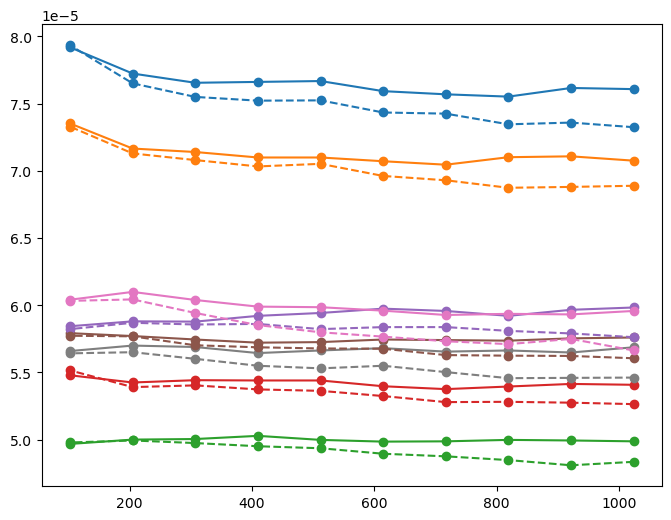

In [67]:
df = pd.read_csv("../outputs/Systematics/BI_window_size_4Pole_Bessel_fit_data.csv")
fig, ax1 = plt.subplots(figsize=(8,6))
lines = []
for i,index_channel in enumerate(np.argsort(channel_ID)):
    channel = channels[index_channel]
    data_channel = df[df["channel"]==channel]
    l,=ax1.plot(data_channel["window_size"]*1e-1, data_channel["BI"], label=f"Channel {channel} indiv nps 1-rp",marker='o')
    lines.append(l)
df = pd.read_csv("../outputs/Systematics/BI_window_size_4Pole_Bessel.csv")
for i,index_channel in enumerate(np.argsort(channel_ID)):
    channel = channels[index_channel]
    data_channel = df[df["channel"]==channel]
    ax1.plot(data_channel["window_size"]*1e-1, data_channel["BI"], label=f"Channel {channel} indiv nps 1-rp",marker='o',ls='--',c=lines[i].get_color())
plt.show()

In [ ]:
BASE = "../"
acceptance = 0.9

for i,index_channel in enumerate(np.argsort(channel_ID)):
    channel = channels[index_channel]
    directory_path = f"{BASE}/outputs/Pileup_filter_functions/channel_{channel}/window_size/"
    for window_size in [2 ** 13 - 6 * 2 ** 9 - 4* i * 2 ** 8 + 5*2 ** 10 for i in range(10)]:
        f1,f2 = np.load(directory_path +
            f"functions_eff{int(acceptance * 100):d}_window_size_{int(window_size):d}_4Pole_Bessel.npy")
        plt.loglog(np.fft.fftfreq(len(f1),1e-4)[:len(f1)//2], f1[:len(f1)//2], label=f"Channel {channel} window {window_size}",alpha=0.5)
        plt.loglog(np.fft.fftfreq(len(f2),1e-4)[:len(f2)//2], f2[:len(f2)//2], alpha=0.5)
    plt.show()

[ 9.98194832e-01 -1.69248009e-03 -7.60466794e+01 -3.39866933e+03
 -2.84286688e+02 -6.47067061e+01 -3.39857582e+03]
[ 1.00223936e+00 -1.69333162e-03 -8.49647726e+01 -3.71443933e+03
 -2.87373682e+02 -7.22332314e+01 -3.09461206e+03]


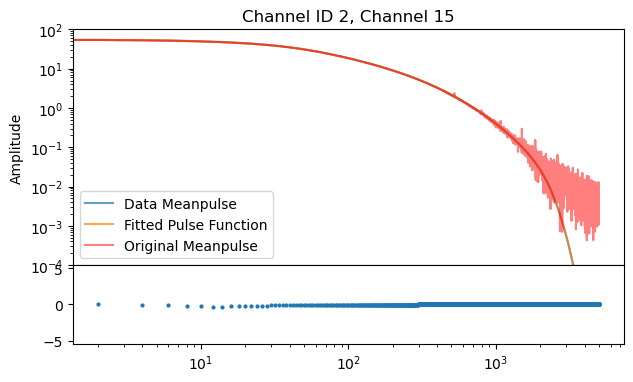

In [54]:
meas_name = "000813_20230628T161508"
StdCuts = [0.0003, 0.0004, 0.0008, 0.0006, 0.0012, 0.0007, 0.00035, 0.0025]
BASE = "../"
from matplotlib.gridspec import GridSpec
fig = plt.figure(figsize=(16, 20))
outer_gs = GridSpec(4, 2, figure=fig, hspace=0.3, wspace=0.25)
from scipy.optimize import curve_fit
for i,index_channel in enumerate(np.argsort(channel_ID)):
    channel = channels[index_channel]
    window_sizes = [2 ** 13 - 6 * 2 ** 9 - i * 4 * 2 ** 8 + 5*2 ** 10 for i in range(10)]
    # window_sizes = [2 ** 13 - 6 * 2 ** 9 - i * 2 ** 10 + 5*2 ** 10 for i in range(10)]
    # fitted_pulse_function = np.fromfile(ds.find_file(f"ch{channel}_fit*.bin",
    #                                                  specific_subdir="RUN9_pulse_injected_new/"))
    # fitted_pulse_function = np.pad(fitted_pulse_function, (4000, 4000), 'constant', constant_values=0)
    meanpulse = np.fromfile(ds.find_file(f"{meas_name}_{channel:03}_???.bin_edmean.bin",
                                         specific_subdir="RUN9_pulse_injected_new/"))
    t = np.arange(-len(meanpulse) // 2, len(meanpulse) // 2) * 1e-4
    p0 = [1, t[np.argmax(meanpulse)], -1000, -1339.1, -237.0, -100, -1000.0]
    fit_fct_pole = lambda x, *params: sim.apply_bessel_to_pulse(x, sim.pulse_pole_zero(x, *params), fc=2500, order=6,
                                                                fs=1e4)
    popt, pcov = curve_fit(fit_fct_pole, t, meanpulse, p0=p0,
                           bounds=([0, -0.5, -5000, -5000, -5000, -5000, -5000], [10, 0.5, 0, 0, 0, 0, 0]))
    fitted_pulse_function = lambda t: fit_fct_pole(t*1e-4, *popt)
    injected_pulse = fitted_pulse_function(np.arange(-len(meanpulse)//2,len(meanpulse)//2))
    print(popt)
    meanpulse_from_data = np.load(f"{BASE}/outputs/meanpulses_build/channel{channel}_meanpulse_build_from_fit_4Pole_Bessel.npy")
    meanpulse_from_data /= np.max(meanpulse_from_data)
    t = np.arange(-len(meanpulse_from_data) // 2, len(meanpulse_from_data) // 2) * 1e-4
    # meanpulse = np.pad(meanpulse, (4000, 4000), 'constant', constant_values=0)
    popt, pcov = curve_fit(fit_fct_pole, t, meanpulse_from_data, p0=p0,
                           bounds=([0, -0.5, -5000, -5000, -5000, -5000, -5000], [10, 0.5, 0, 0, 0, 0, 0]))
    print(popt)
    fitted_pulse_function_on_data = lambda t: fit_fct_pole(t * 1e-4, *popt)
    fitted_pulse_on_data = fitted_pulse_function_on_data(np.arange(-len(meanpulse)//2,len(meanpulse)//2))
    inner_gs = outer_gs[i//2, i%2].subgridspec(
            2, 1,
            height_ratios=[3, 1],
            hspace=0
        )
    ax1 = fig.add_subplot(inner_gs[0])
    ax1.set_title(f"Channel ID {channel_ID[index_channel]}, Channel {channel}")
    ax2 = fig.add_subplot(inner_gs[1], sharex=ax1)
    axs = ax1,ax2
    plots.plot_meanpulse_fit_freq(fitted_pulse_on_data,injected_pulse,axs,["Data Meanpulse","Fitted Pulse Function"])
    ax1.loglog(np.fft.rfftfreq(len(meanpulse),1e-4),np.abs(np.fft.rfft(meanpulse)), label='Original Meanpulse',c='red',alpha=0.5)
    ax1.legend()
    break

/tmp/ipykernel_30209/4156330702.py:12: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  err[err>1e-5]=0


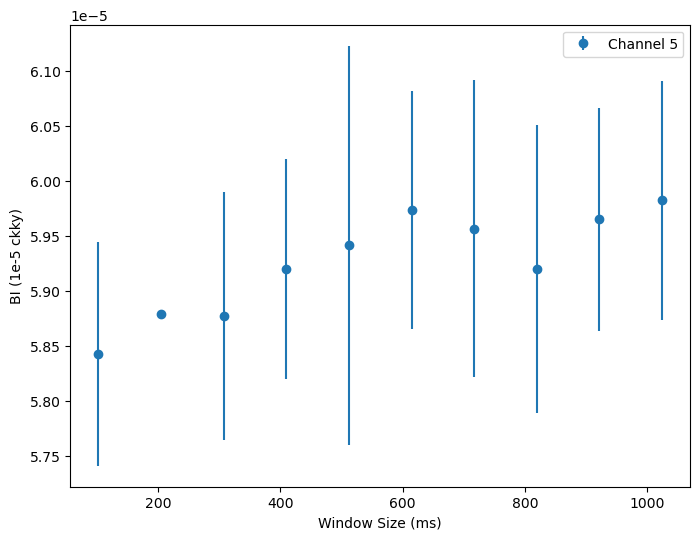

In [253]:
df = pd.read_csv("../outputs/Systematics/BI_window_size_4Pole_Bessel_fit_data.csv")
# df_bis = pd.read_csv("../outputs/Systematics/BI_window_size_4Pole_Bessel_fit_data_bis.csv")

df.update(df_bis)
fig, ax1 = plt.subplots(figsize=(8,6))
lines = []
for i,index_channel in enumerate(np.argsort([1])):
    # channel = channels[index_channel]
    channel = 5
    data_channel = df[df["channel"]==channel]
    err = data_channel["BI_err"]
    err[err>1e-5]=0
    ax1.errorbar(data_channel["window_size"]*1e-1,data_channel["BI"],yerr = err , label=f"Channel {channel}",marker='o',ls="")
    ax1.set_xlabel("Window Size (ms)")
    ax1.set_ylabel("BI (1e-5 ckky)")
plt.legend()
    # l,=ax1.plot(data_channel["window_size"]*1e-1, data_channel["1-rp"], label=f"Channel {channel} indiv nps 1-rp",marker='o')
    # ax1.plot(data_channel["window_size"]*1e-1, data_channel["J"], label=f"Channel {channel} indiv nps 1-rp",marker='o',ls='--',c=l.get_color())

Using device: cpu
Channel 3, window size 10240: BI = 5.36752 ± 0.00000, 1-rp = 0.20349 ± 0.00471, J = 0.20025


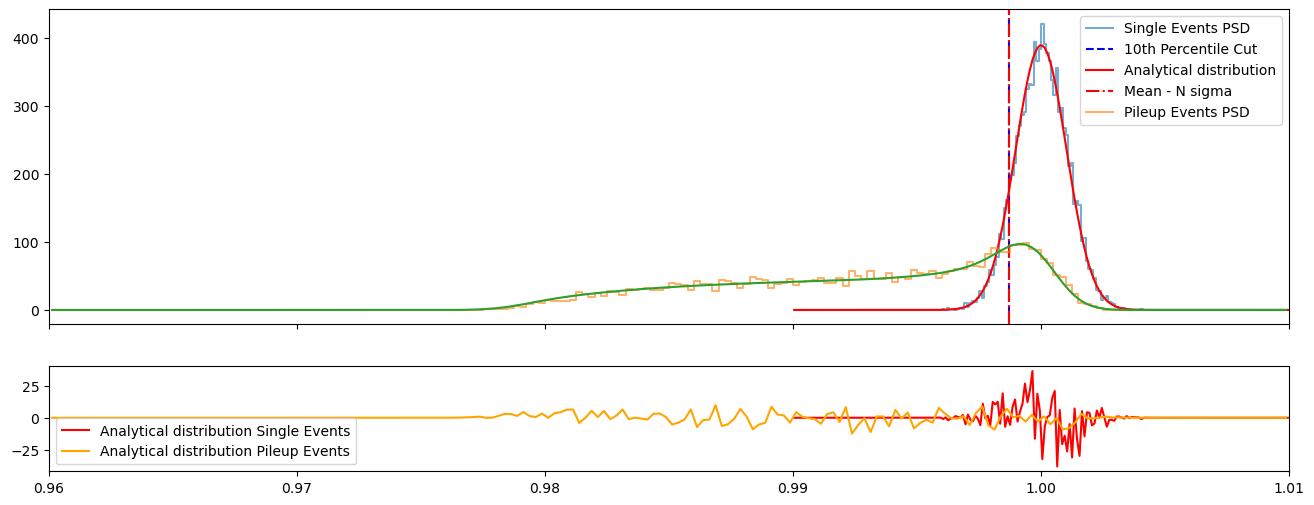

Channel 5, window size 10240: BI = 5.60257 ± 0.00000, 1-rp = 0.21240 ± 0.00486, J = 0.21145


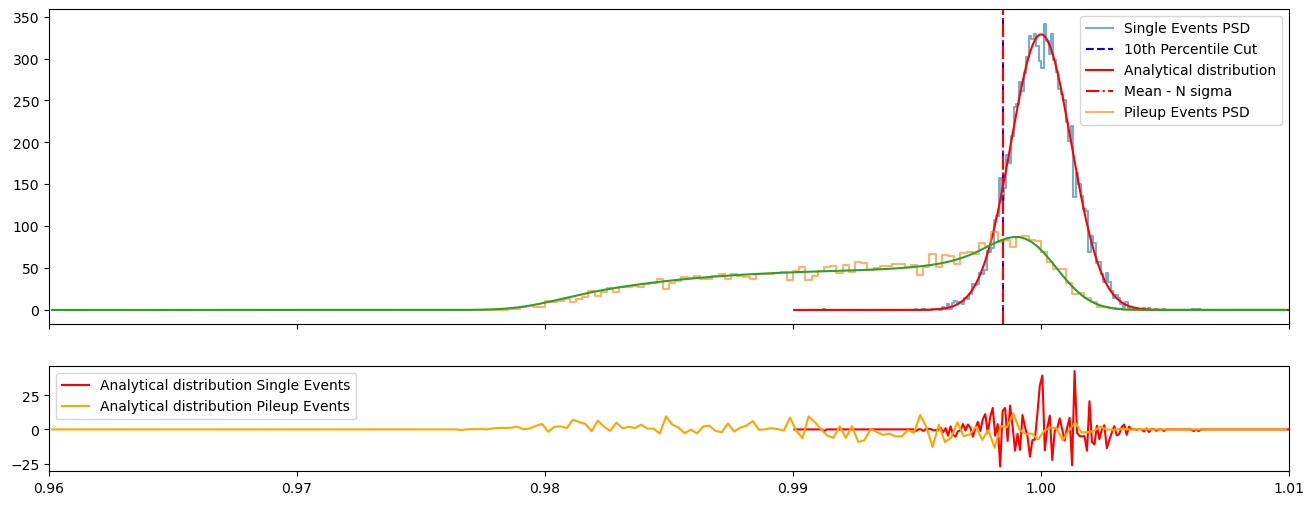

Channel 9, window size 10240: BI = 5.93422 ± 0.00000, 1-rp = 0.22498 ± 0.00497, J = 0.21803


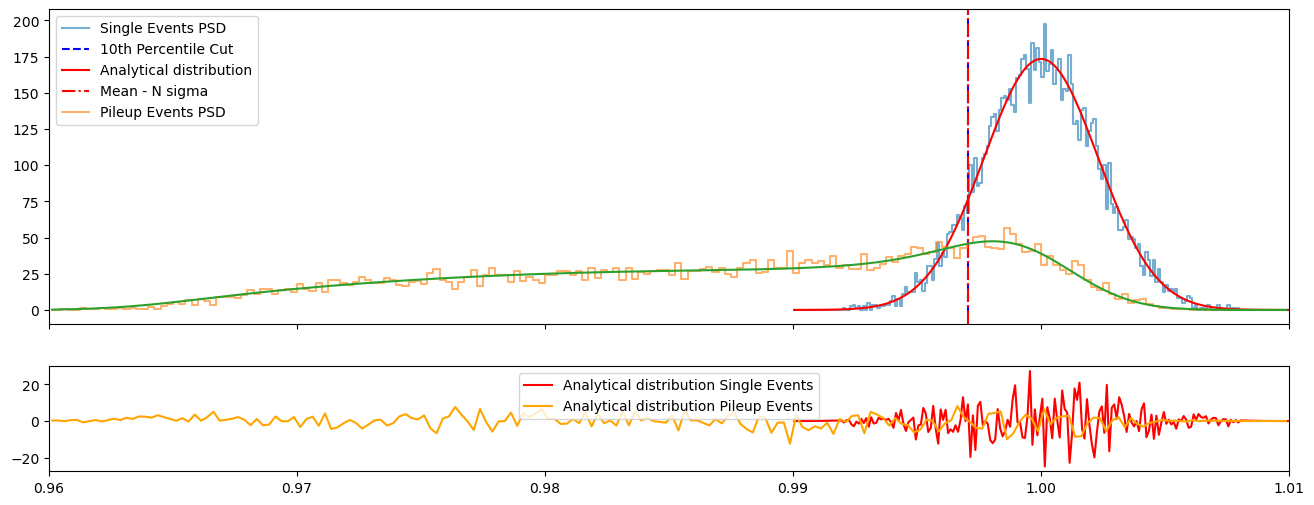

Channel 11, window size 10240: BI = 5.64443 ± 0.00000, 1-rp = 0.21399 ± 0.00484, J = 0.20482


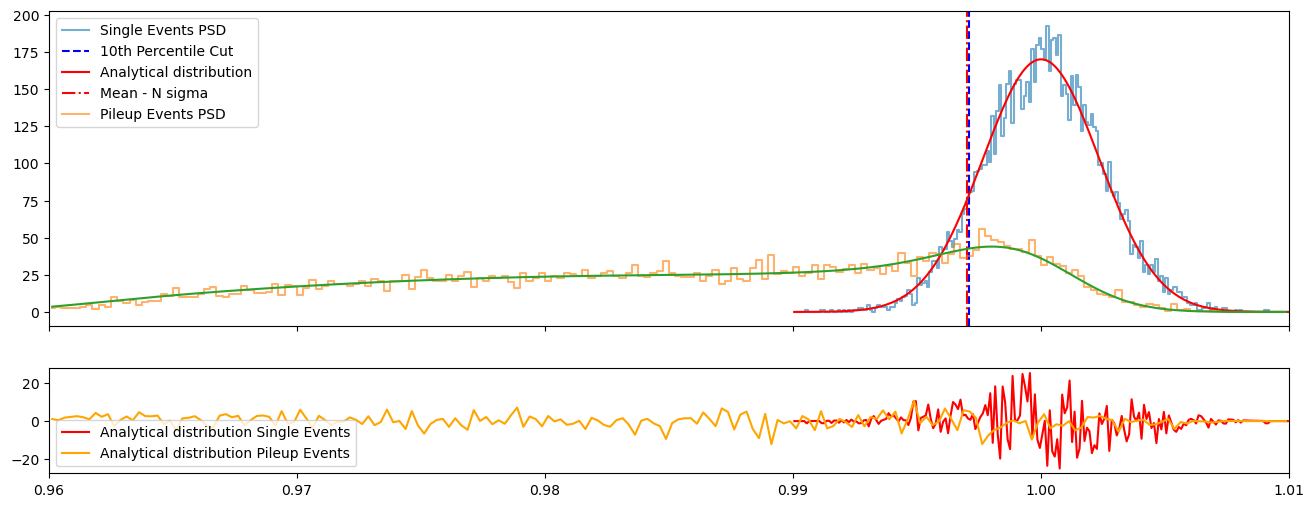

Channel 13, window size 10240: BI = 5.01656 ± 0.00000, 1-rp = 0.19019 ± 0.00459, J = 0.18606


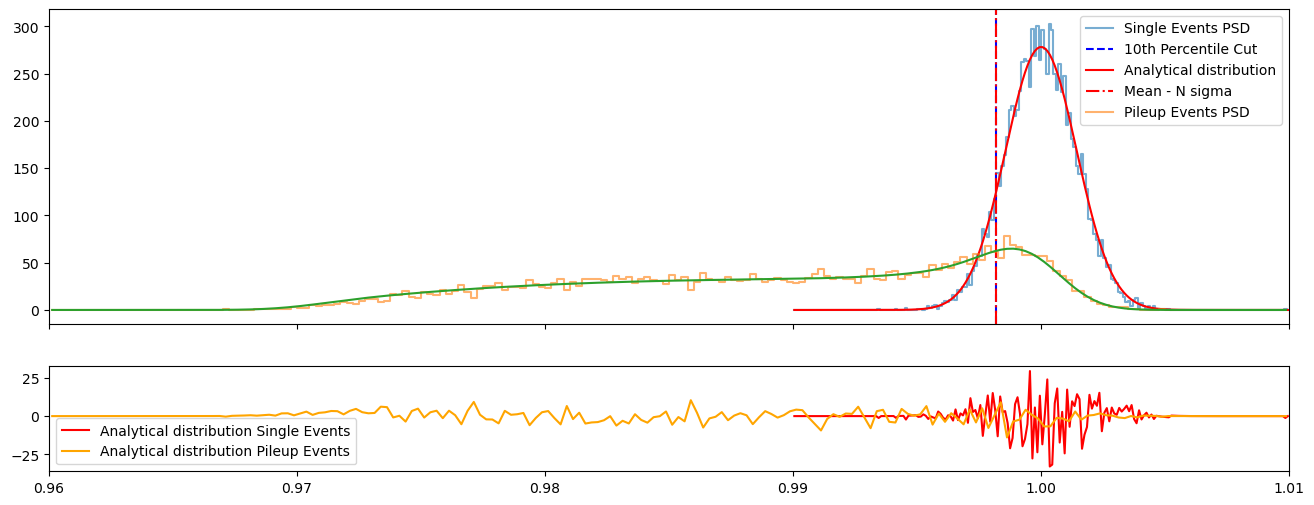

Channel 15, window size 10240: BI = 7.29622 ± 0.00000, 1-rp = 0.27661 ± 0.00550, J = 0.27697


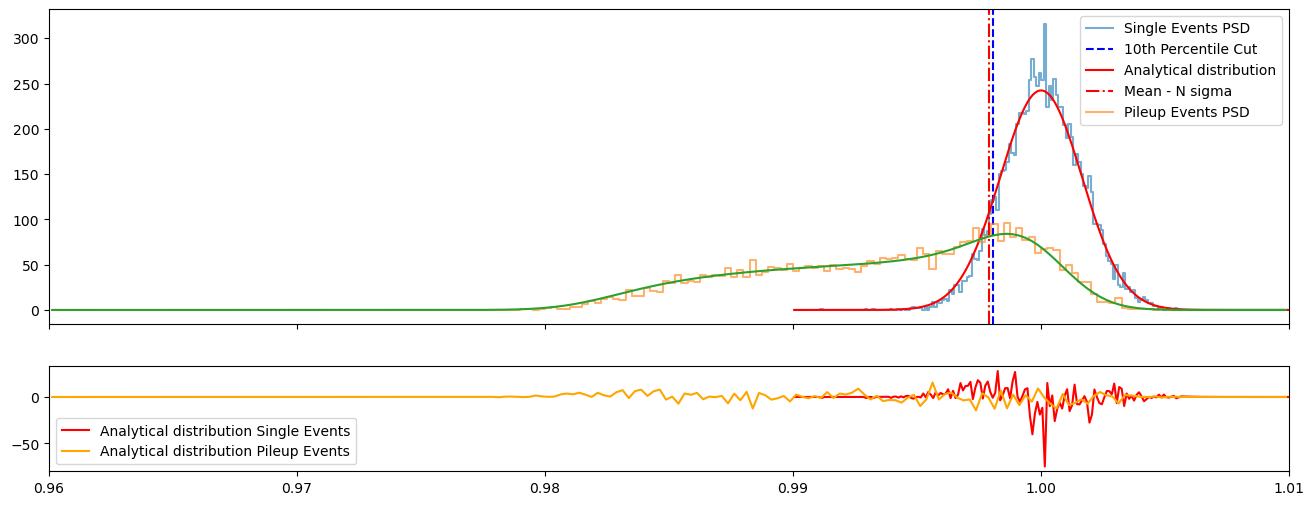

Channel 17, window size 10240: BI = 5.48022 ± 0.00000, 1-rp = 0.20776 ± 0.00481, J = 0.19757


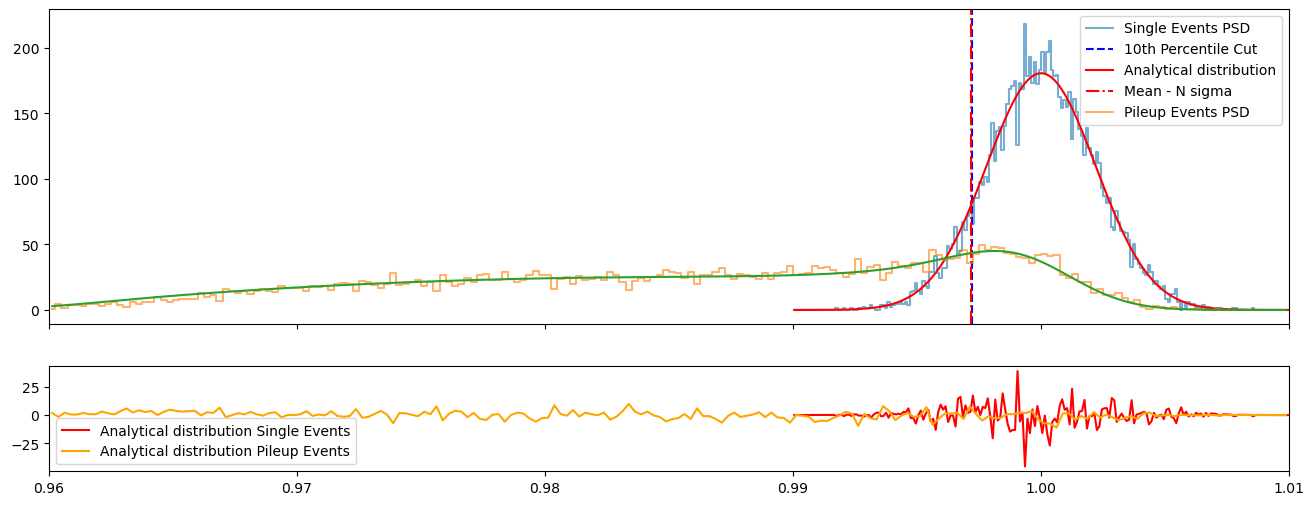

Channel 19, window size 10240: BI = 6.89052 ± 0.00000, 1-rp = 0.26123 ± 0.00531, J = 0.25645


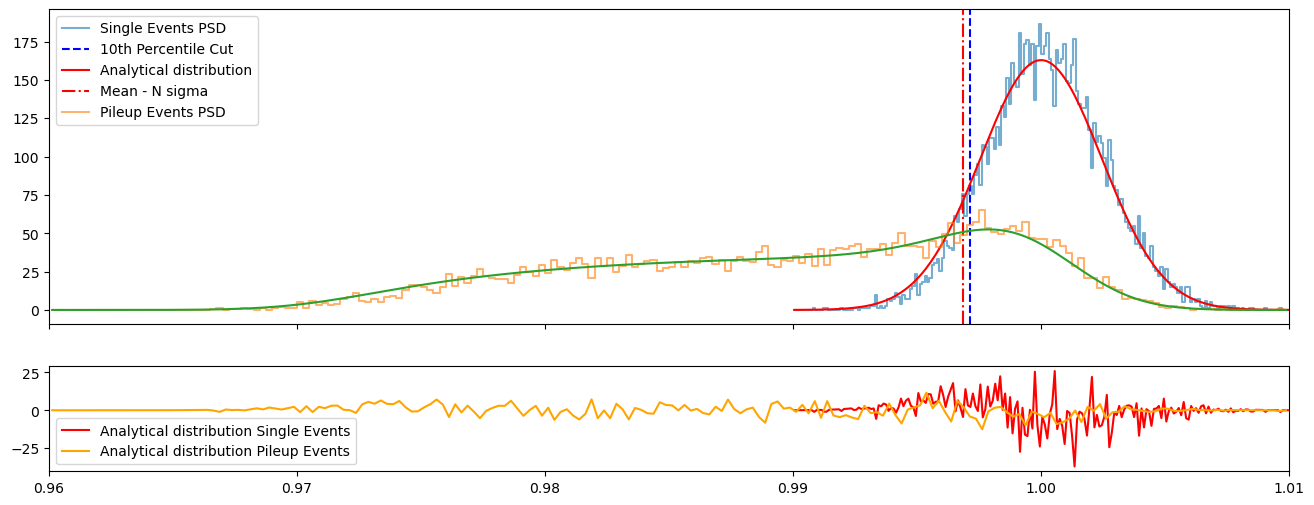

In [25]:
BASE = "../"
from scipy.optimize import curve_fit
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)
StdCuts = [0.0003, 0.0004, 0.0008, 0.0006, 0.0012, 0.0007, 0.00035, 0.0025]
channels = [3, 5, 9, 11, 13, 15, 17, 19]
window_size_data = []
channel_data = []

BI_uncertainties, rp_uncertainties = [], []
BIs = []
rps = []
Js = []
acceptance = 0.9
n_deriv = 0
meas_name = "000813_20230628T161508"
for channel, StdCut in zip(channels, StdCuts):
    window_sizes = [2 ** 13 - 6 * 2 ** 9 - i * 4 * 2 ** 8 + 5*2 ** 10 for i in range(10)]
    meanpulse = np.fromfile(ds.find_file(f"{meas_name}_{channel:03}_???.bin_edmean.bin",
                                         specific_subdir="RUN9_pulse_injected_new/"))
    t = np.arange(-len(meanpulse) // 2, len(meanpulse) // 2) * 1e-4
    p0 = [1, t[np.argmax(meanpulse)], -1000, -1339.1, -237.0, -100, -1000.0]
    fit_fct_pole = lambda x, *params: sim.apply_bessel_to_pulse(x, sim.pulse_pole_zero(x, *params), fc=2500, order=6,
                                                                fs=1e4)
    popt, pcov = curve_fit(fit_fct_pole, t, meanpulse, p0=p0,
                           bounds=([0, -0.5, -5000, -5000, -5000, -5000, -5000], [10, 0.5, 0, 0, 0, 0, 0]))
    fitted_pulse_function = lambda t: fit_fct_pole(t*1e-4, *popt)
    dataset_single_name = "pup_n1-d0_000813_20230628T161508"
    file_path_single, path_pos_single = ds.find_files(meas_name, dataset_single_name, channel,
                                                      specific_subdir="RUN9_pulse_injected_new/")
    #[:-4]+f"_single_amp.pos"
    data_single = ds.CachedBinaryDataset_withgenerated(file_path_single, path_pos_single, window_sizes[0],
                                                       pulse=fitted_pulse_function,
                                                       n_windows=2**13, win_shift=window_sizes[0]//2,
                                                       )

    dataset_pileup_name = "pup_n1-d8_000813_20230628T161508"
    #[:-4]+f"_r05_dt03.pos"
    file_path_pileup, path_pos_pileup = ds.find_files(meas_name, dataset_pileup_name, channel,
                                                      specific_subdir="RUN9_pulse_injected_new/")
    data_pileup = ds.CachedBinaryDataset_withgenerated(file_path_pileup, path_pos_pileup, window_sizes[0],
                                                       pulse=fitted_pulse_function,
                                                       n_windows=2**13, win_shift=window_sizes[0]//2)

    _, _, _, _, pulse_factor, _ = ds.get_channel_specs(channel, n_deriv=n_deriv, window_fct=np.hanning)
    signal_amp = ds.get_amp_Q_val(channel) * pulse_factor
    t_min, t_max, N_t = -8e-4, 8e-4, 100
    r_min, r_max, N_r = 0., .5, 50

    ratio_distribution = pdf_ratio2b(np.linspace(r_min, r_max, N_r))
    ratio_distribution /= np.mean(ratio_distribution)

    # meanpulse = np.load(f"{BASE}/outputs/meanpulses_build/channel{channel}_meanpulse_build_from_fit_4Pole_Bessel.npy")
    # meanpulse /= np.max(meanpulse)
    # t = np.arange(-len(meanpulse) // 2, len(meanpulse) // 2) * 1e-4
    # p0 = [1, t[np.argmax(meanpulse)], -1000, -1339.1, -237.0, -100, -1000.0]
    # popt, pcov = curve_fit(fit_fct_pole, t, meanpulse, p0=p0,
    #                        bounds=([0, -0.5, -5000, -5000, -5000, -5000, -5000], [10, 0.5, 0, 0, 0, 0, 0]))
    # fitted_pulse_function_on_data = lambda t: fit_fct_pole(t * 1e-4, *popt)

    t_torch = torch.linspace(t_min, t_max, N_t, dtype=torch.cfloat, device=device)
    r_torch = torch.linspace(r_min, r_max, N_r, dtype=torch.cfloat, device=device)
    ratio_distribution_torch = torch.tensor(ratio_distribution, dtype=torch.cfloat, device=device)

    for window_size in window_sizes:
        data_single.set_win_length(window_size, win_shift=window_size // 2)
        data_pileup.set_win_length(window_size, win_shift=window_size // 2)
        nps_bis = np.load(f"{BASE}/results/NPS_study/NPS_channel{channel}_win{window_size}_cut{StdCut}_{meas_name}.npy")
        nps_bis *= (8./3.)  # Adjust for Hann window effect
        meanpulse_bis = fitted_pulse_function( np.arange(-window_size // 2, window_size // 2))
        S, w, H_unit = ds.compute_H(meanpulse_bis, nps_bis, np.hanning)
        # Convert all arrays to torch tensors on GPU
        N_sigma = norm.ppf(1 - (1 - acceptance) * 100 / 100)
        S_torch = torch.tensor(S, dtype=torch.cfloat, device=device)
        H_unit_torch = torch.tensor(H_unit, dtype=torch.cfloat, device=device)
        w_torch = torch.tensor(w, dtype=torch.cfloat, device=device)
        nps_torch = torch.tensor(nps_bis, dtype=torch.cfloat, device=device)
        signal_amp_torch = torch.tensor(signal_amp, dtype=torch.float32, device=device)
        f1_opt, f2_opt = np.load(
            f"{BASE}/outputs/Pileup_filter_functions/channel_{channel}/window_size/"
            f"functions_eff{int(acceptance * 100):d}_window_size_{int(window_size):d}_4Pole_Bessel_fit_data.npy"
        )
        f1_t = torch.tensor(f1_opt, dtype=torch.float32, device=device)
        f2_t = torch.tensor(f2_opt, dtype=torch.float32, device=device)
        S_H_delayed, S_H, S2_over_nps = an.precompute_constants(S_torch, H_unit_torch, w_torch, t_torch, nps_torch)

        f1_t /= torch.mean(f1_t * S_H).real
        f2_t /= torch.mean(f2_t * S_H).real
        J ,A, muY, sigmaY = an.compute_J(f1_t, f2_t, S_H_delayed, r_torch, S_H, S2_over_nps, signal_amp_torch, ratio_distribution_torch,N_sigma=N_sigma, full_output=True)
        
        BI, rp,sigma_rp, sigma_BI, PSD_pileup, PSD_single, Amp_1_pileup, Amp_2_pileup, Amp_1_single, Amp_2_single = an.compute_BI_torch(
            data_pileup,
            data_single,
            acceptance,
            H_unit_torch,
            f1_t,
            f2_t,
            window_fct=np.hanning,
            n_deriv=0,
            compute_uncertainty=True,
            full_output=True,
            batch_size=2048 * 2,
            use_loader=False
        )
        print(f"Channel {channel}, window size {window_size}: BI = {BI*1e5:.5f} ± {sigma_BI:.5f}, 1-rp = {1-rp:.5f} ± {sigma_rp:.5f}, J = {J:.5f}")
        break
    plots.plot_PSD_distribution(PSD_single, PSD_pileup, muY, sigmaY, ratio_distribution, N_sigma)

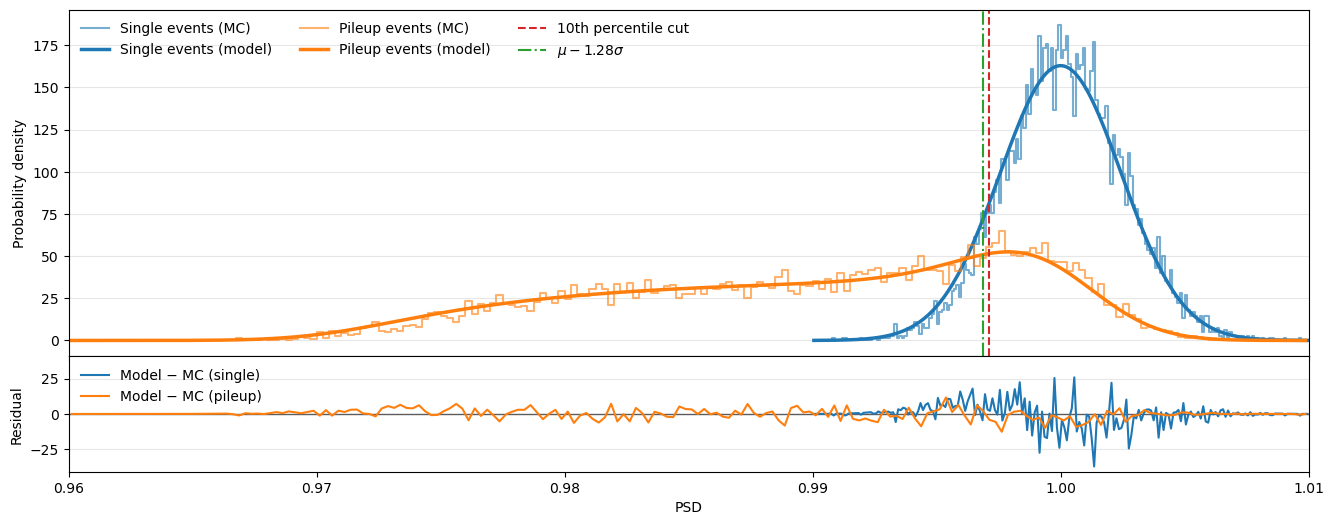

In [79]:
plots.plot_PSD_distribution(PSD_single, PSD_pileup, muY, sigmaY, ratio_distribution, N_sigma)

tensor(0.2612) tensor(0.2564) tensor(0.0183)


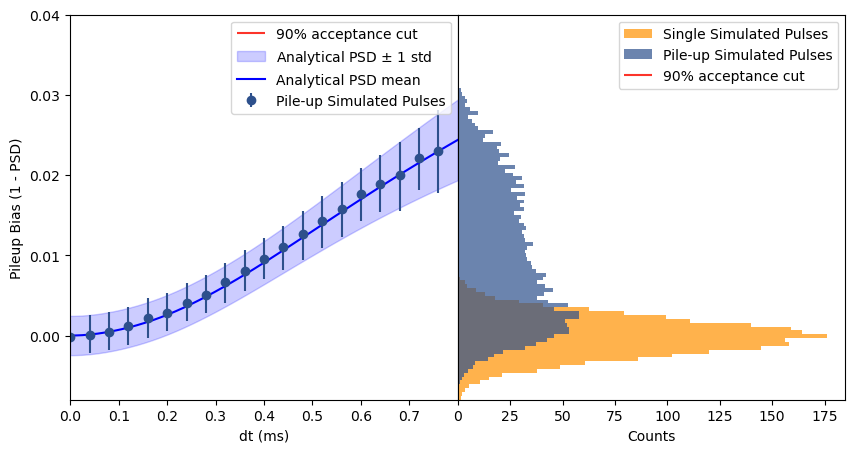

In [68]:
from src.plots import plot_biais_vs_dt
import matplotlib.pyplot as plt
dt_pileup = np.loadtxt(path_pos_pileup)[:4096*2,-1]
S_H_delayed, S_H, S2_over_nps = an.precompute_constants(S_torch, H_unit_torch, w_torch, t_torch, nps_torch)
J ,A, muY, sigmaY = an.compute_J(f1_t, f2_t, S_H_delayed, r_torch, S_H, S2_over_nps, signal_amp_torch, ratio_distribution_torch,N_sigma=N_sigma, full_output=True)
print(1-rp,J,(1-rp-J)/ (1-rp))
mu = torch.mean(ratio_distribution_torch[:,None]*(1-muY.real), dim = 0).numpy().real
sigma = torch.sqrt(torch.mean(ratio_distribution_torch[:,None]*sigmaY**2, dim = 0)+torch.mean(ratio_distribution_torch[:,None]*(1-muY.real)**2, dim = 0)-mu**2).numpy().real
fig,ax,ax1=plot_biais_vs_dt(PSD_single.real, PSD_pileup.real, dt_pileup,cut=1,bins=20)
ax.fill_between(t_torch.numpy().real*1e3, (mu-sigma).real, (mu+sigma).real, alpha=0.2, color='blue', label='Analytical PSD $\pm$ 1 std')
ax.plot(t_torch.numpy().real*1e3, mu.real, color='blue', label='Analytical PSD mean')
ax.set_xlim(0,0.8)
ax.set_ylim(-0.008,0.04)
ax.legend()
plt.show()

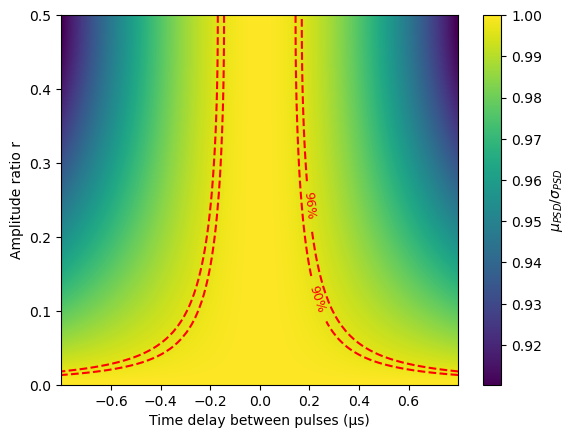

In [69]:
# plt.imshow(sigmaY.numpy(), extent=[t_torch[0].real*1e4, t_torch[-1].real*1e4, r_torch[0].real, r_torch[-1].real],
#               aspect='auto', origin='lower')
# plt.colorbar(label='Sigma Y')
# plt.show()
# plt.imshow(muY.numpy(), extent=[t_torch[0].real*1e4, t_torch[-1].real*1e4, r_torch[0].real, r_torch[-1].real],
#               aspect='auto', origin='lower')
# plt.colorbar(label='Mean Y')
# plt.show()
# plt.imshow(np.concatenate([ratio_distribution[:,None]]*N_t,axis = 1), extent=[t_torch[0].real*1e4, t_torch[-1].real*1e4, r_torch[0].real, r_torch[-1].real],
#               aspect='auto', origin='lower',interpolation = 'bilinear')
# plt.colorbar(label='r_t distribution')
# plt.show()
Z = (muY/sigmaY).numpy()*sigmaY[0,0].numpy()/muY[0,0].numpy()
extent = [
    t_torch[0].real * 1e3,
    t_torch[-1].real * 1e3,
    r_torch[0].real,
    r_torch[-1].real
]
plt.imshow(Z, extent=extent,
              aspect='auto', origin='lower',interpolation = 'bilinear')

plt.colorbar(label='$\mu_{PSD}/\sigma_{PSD}$')
from scipy.stats import norm

levels_info = [
    (norm.ppf(0.90), "90%",0.3),
    (norm.ppf(0.96), "96%",0.5),
]

for N_sig, label, pos in levels_info:
    v0 = Z[0, 0] - N_sig*sigmaY[0,0].numpy()/muY[0,0].numpy()

    cs = plt.contour(
        Z,
        levels=[v0],
        extent=extent,
        colors='red',
        linewidths=1.5,
        linestyles='--'
    )

    plt.clabel(
        cs,
        fmt={v0: label},
        manual= [(t_torch[-1].real * 1e3 * (1-pos), r_torch[-1].real * pos)],
        inline=True,
        inline_spacing=10,
        fontsize=9
    )
plt.xlabel("Time delay between pulses (µs)")
plt.ylabel("Amplitude ratio r")
plt.show()

In [82]:
StdCuts = [0.0003, 0.0004, 0.0008, 0.0006, 0.0012, 0.0007, 0.00035, 0.0025]
channels = [3, 5, 9, 11, 13, 15, 17, 19]
n_deriv = 0
import os
meas_name = "000813_20230628T161508"

for channel, StdCut in zip(channels, StdCuts):
    window_sizes = [2 ** 13 - 6 * 2 ** 9 - i * 4 * 2 ** 8 + 5*2 ** 10 for i in range(10)]
    for window_size in window_sizes:
        os.rename(f"{BASE}/outputs/NPS_study/NPS_channel{channel}_win{window_size}_cut{StdCut}_{meas_name}.npy",
                  f"{BASE}/outputs/NPS_study/NPS_channel{channel}_win{window_size}_{meas_name}.npy")
        print(f"Renamed channel {channel} window size {window_size}")

In [73]:
import sys
from pathlib import Path
# Add src to Python path dynamically
BASE = Path("../")
sys.path.append(str(BASE))
import numpy as np
import src.analysis as an
import src.dataset as ds
import src.simulation as sim
from utility.double_beta_spectrum import pdf_ratio2b
import torch
from scipy.stats import norm
from scipy.optimize import curve_fit
import os
# Ensure we have GPU available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)
StdCuts = [0.0003, 0.0004, 0.0008, 0.0006, 0.0012, 0.0007, 0.00035, 0.0025]
channels = [3, 5, 9, 11, 13, 15, 17, 19]
fp_model = lambda *params: sim.filtered_pulse_model(*params, fc = 2500, order = 6)

BIs = []
BI_uncertainties = []
rps = []
rp_uncertainties = []
Js = []
channel_data = []
pulse_center_ratios_data = []
pulse_center_ratios = [i*0.05 for i in range(1,20)]
data_fit = np.loadtxt(f"{BASE}/outputs/fits/pulse_fit_params_bessel.txt")

for channel, StdCut in zip(channels, StdCuts):
    window_size = 4096
    meas_name = "000813_20230628T161508"
    # fitted_pulse_function = np.fromfile(ds.find_file(f"ch{channel}_fit*.bin",
    #                                                  specific_subdir = "RUN9_pulse_injected_new/"))
    meanpulse = np.fromfile(ds.find_file(f"{meas_name}_{channel:03}_???.bin_edmean.bin",
                                     specific_subdir="RUN9_pulse_injected_new/"))
    t = np.arange(-len(meanpulse) // 2, len(meanpulse) // 2) * 1e-4
    fit_fct_pole = lambda x, *params: sim.apply_bessel_to_pulse(x, sim.pulse_pole_zero(x, *params), fc=2500, order=6,
                                                                fs=1e4)
    popt = data_fit[data_fit[:,0]==channel,1:][0]
    fitted_pulse_function = lambda t: fit_fct_pole(t*1e-4, *popt)
    dataset_single_name = "pup_n1-d0_000813_20230628T161508"
    file_path_single, path_pos_single = ds.find_files(meas_name, dataset_single_name, channel,
                                                      specific_subdir = "RUN9_pulse_injected_new/")
    data_single = ds.CachedBinaryDataset_withgenerated(file_path_single, path_pos_single, window_size*2,
                                                       pulse = fitted_pulse_function,
                                                       n_windows = 1024, win_shift = 0)
    data_single.set_win_length(4096)
    dataset_pileup_name = "pup_n1-d8_000813_20230628T161508"
    file_path_pileup, path_pos_pileup = ds.find_files(meas_name, dataset_pileup_name, channel,
                                                      specific_subdir = "RUN9_pulse_injected_new/")
    data_pileup = ds.CachedBinaryDataset_withgenerated(file_path_pileup, path_pos_pileup, window_size*2,
                                                       pulse = fitted_pulse_function,
                                                       n_windows = 1024, win_shift = 0)
    data_pileup.set_win_length(4096)
    nps = np.load(f"{BASE}/outputs/NPS_study/NPS_channel{channel}_win{window_size}_{meas_name}.npy")
    nps *= (8./3.)  # Adjust for Hann window effect
    acceptance = 0.9
    n_deriv = 0
    signal_amp = ds.get_amp_Q_val(channel)

    t_min, t_max, N_t = 0, 8e-4, 100
    r_min, r_max, N_r = 0., .5, 25

    ratio_distribution = pdf_ratio2b(np.linspace(r_min, r_max, N_r))
    ratio_distribution /= np.mean(ratio_distribution)

    t_torch = torch.linspace(t_min, t_max, N_t, dtype = torch.cfloat, device = device)
    r_torch = torch.linspace(r_min, r_max, N_r, dtype = torch.cfloat, device = device)
    ratio_distribution_torch = torch.tensor(ratio_distribution, dtype = torch.cfloat, device = device)

    N_sigma = norm.ppf(1 - (1 - acceptance) * 100 / 100)
    signal_amp_torch = torch.tensor(signal_amp, dtype = torch.float32, device = device)
    Ss = []
    for pulse_center_ratio in pulse_center_ratios:
        data_single.set_fracshift(0.5-pulse_center_ratio)
        data_pileup.set_fracshift(0.5-pulse_center_ratio)
        meanpulse = an.build_mean_pulse(data_single, rms_thr=StdCut, batch_size=2048, device=device,
                                        pulse_center_ratio=pulse_center_ratio,
                                         use_loader=False).cpu().numpy()
        _, _, H_unit = an.compute_H(meanpulse, nps,  lambda x: fn.asymmetric_hann(x, pulse_center_ratio))
        H_unit_torch = torch.tensor(H_unit, dtype=torch.cfloat, device=device)
        meanpulse = an.build_mean_pulse_filteralignement(data_single, rms_thr=StdCut,
                                                         pulse_center_ratio=pulse_center_ratio,
                                                         H=H_unit_torch, batch_size=2048,
                                                         device=device, use_loader=False).cpu().numpy()
        meanpulse /= np.max(meanpulse)
        S, w, H_unit = an.compute_H(meanpulse, nps, lambda x: fn.asymmetric_hann(x, pulse_center_ratio))
        Ss.append(S)

        S_torch = torch.tensor(S, dtype = torch.cfloat, device = device)
        H_unit_torch = torch.tensor(H_unit, dtype = torch.cfloat, device = device)
        w_torch = torch.tensor(w, dtype = torch.cfloat, device = device)
        nps_torch = torch.tensor(nps, dtype = torch.cfloat, device = device)
        
        f1_opt, f2_opt = np.load(
            f"{BASE}/outputs/Pileup_filter_functions/channel_{channel}/window_size/"
            f"functions_eff{int(acceptance * 100):d}_window_size_{int(window_size):d}_4Pole_Bessel.npy"
        )
        f1_t = torch.tensor(f1_opt, dtype=torch.float32, device=device)
        f2_t = torch.tensor(f2_opt, dtype=torch.float32, device=device)
        f1_opt, f2_opt, J_values = an.optimize_filters(S_torch, H_unit_torch, w_torch, t_torch, r_torch, nps_torch,
                                                       signal_amp_torch, ratio_distribution_torch, N_sigma=N_sigma,
                                                       n_trials=100, verbose=True,f1_init = f1_t, f2_init = f2_t)
        S_H_delayed, S_H, S2_over_nps = an.precompute_constants(S_torch, H_unit_torch, w_torch, t_torch, nps_torch)

        J, A, muY, sigmaY = an.compute_J(f1_t, f2_t, S_H_delayed, r_torch, S_H, S2_over_nps, signal_amp_torch, ratio_distribution_torch,
                         N_sigma=N_sigma, full_output=True)
        BI, rp, sigma_rp, sigma_BI = an.compute_BI_torch(
            data_pileup,
            data_single,
            acceptance,
            H_unit_torch,
            f1_t,
            f2_t,
            window_fct= lambda x: fn.asymmetric_hann(x, pulse_center_ratio),
            n_deriv=0,
            compute_uncertainty=True,
            batch_size=2048 * 2,
            use_loader=False
        )
        print(f"Channel {channel}, pulse center ratio {pulse_center_ratio:.2f}, initial J = {J:.5f}, BI = {BI*1e5:.5f} ± {sigma_BI*1e5:.5f}, 1-rp = {1 - rp:.5f} ± {sigma_rp:.5f}")
        print(sigmaY[0,0].numpy())
        #plt.loglog(H_unit_torch.abs().cpu().numpy(), label=f"{pulse_center_ratio}")
    break
#plt.legend()

Using device: cpu
Step 0: J = 0.187185
Step 10: J = 0.186614
Step 20: J = 0.185988
Step 30: J = 0.185427
Step 40: J = 0.184847
Step 50: J = 0.184273
Step 60: J = 0.183692
Step 70: J = 0.183123
Step 80: J = 0.182524
Step 90: J = 0.181906
Final: J = 0.181315
Channel 3, pulse center ratio 0.05, initial J = 0.18875, BI = 4.86844 ± 0.90409, 1-rp = 0.18457 ± 0.03428
0.00086402684
Step 0: J = 0.186760
Step 10: J = 0.186203
Step 20: J = 0.185607
Step 30: J = 0.185023
Step 40: J = 0.184467
Step 50: J = 0.183898
Step 60: J = 0.183350
Step 70: J = 0.182768
Step 80: J = 0.182176
Step 90: J = 0.181558
Final: J = 0.180953
Channel 3, pulse center ratio 0.10, initial J = 0.18833, BI = 4.97148 ± 0.32825, 1-rp = 0.18848 ± 0.01244
0.0008672922
Step 0: J = 0.186710
Step 10: J = 0.186161
Step 20: J = 0.185545
Step 30: J = 0.184968
Step 40: J = 0.184398
Step 50: J = 0.183838
Step 60: J = 0.183269
Step 70: J = 0.182693
Step 80: J = 0.182080
Step 90: J = 0.181435
Final: J = 0.180846
Channel 3, pulse center ra

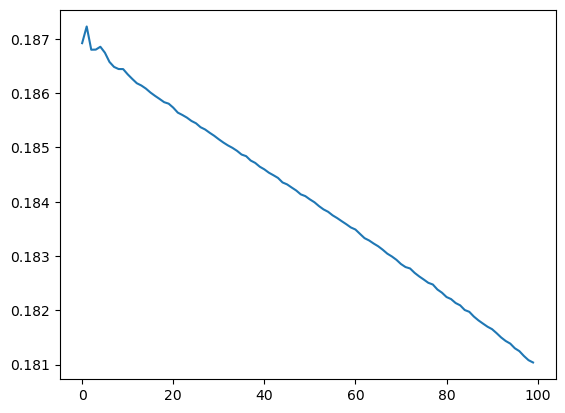

In [76]:
plt.plot(J_values)

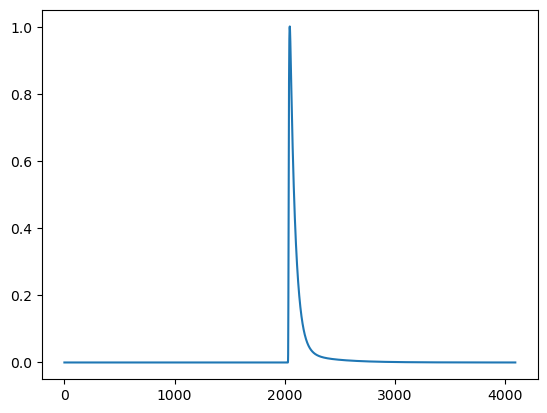

In [70]:
data_fit = np.loadtxt(f"{BASE}/outputs/fits/pulse_fit_params_bessel.txt")
popt = data_fit[data_fit[:,0]==channel,1:][0]
fitted_pulse_function = lambda x: sim.apply_bessel_to_pulse(x*1e-4, sim.pulse_pole_zero(x*1e-4, *popt), fc = 2500,
                                                                order = 6,
                                                                fs = 1e4)
popt = data_fit[data_fit[:,0]==channel,1:][0]
plt.plot(fitted_pulse_function(np.arange(-2048,2048)), label="Fitted Pulse Function")

In [65]:
t

array([-0.25  , -0.2499, -0.2498, ...,  0.2497,  0.2498,  0.2499])

In [42]:
import sys
from pathlib import Path
# Add src to Python path dynamically
BASE = Path("../")
sys.path.append(str(BASE))
import numpy as np
import src.analysis as an
import src.dataset as ds
import src.simulation as sim
from utility.double_beta_spectrum import pdf_ratio2b
import torch
from scipy.stats import norm
from scipy.optimize import curve_fit
import os
# Ensure we have GPU available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)
StdCuts = [0.0003, 0.0004, 0.0008, 0.0006, 0.0012, 0.0007, 0.00035, 0.0025]
channels = [3, 5, 9, 11, 13, 15, 17, 19]
fp_model = lambda *params: sim.filtered_pulse_model(*params, fc = 2500, order = 6)

BIs = []
BI_uncertainties = []
rps = []
rp_uncertainties = []
Js = []
channel_data = []
pulse_center_ratios_data = []
pulse_center_ratios = [i*0.05 for i in range(1,20)]
popts = []
for channel, StdCut in zip(channels, StdCuts):
    window_size = 4096
    meas_name = "000813_20230628T161508"
    # fitted_pulse_function = np.fromfile(ds.find_file(f"ch{channel}_fit*.bin",
    #                                                  specific_subdir = "RUN9_pulse_injected_new/"))
    meanpulse = np.fromfile(ds.find_file(f"{meas_name}_{channel:03}_???.bin_edmean.bin",
                                     specific_subdir="RUN9_pulse_injected_new/"))
    t = np.arange(-len(meanpulse) // 2, len(meanpulse) // 2) * 1e-4
    p0 = [1, t[np.argmax(meanpulse)], -1000, -1339.1, -237.0, -100, -1000.0]
    fit_fct_pole = lambda x, *params: sim.apply_bessel_to_pulse(x, sim.pulse_pole_zero(x, *params), fc=2500, order=6,
                                                                fs=1e4)
    popt, pcov = curve_fit(fit_fct_pole, t, meanpulse, p0=p0,
                           bounds=([0, -0.5, -5000, -5000, -5000, -5000, -5000], [10, 0.5, 0, 0, 0, 0, 0]))
    popts.append(popt)
np.savetxt(f"{BASE}/outputs/fits/pulse_fit_params_bessel.txt", np.array(popts))

Using device: cpu


In [57]:
data = np.loadtxt(f"{BASE}/outputs/fits/pulse_fit_params_bessel.txt")
data[data[:,0]==channel,1:]

array([[ 9.98403279e-01, -1.27817313e-03, -4.76424113e+02,
        -8.11384805e+02, -4.38077499e+03, -2.29658170e+02,
        -4.38107234e+03]])

In [55]:
data[0]

array([ 3.00000000e+00,  1.00219529e+00, -1.88539896e-03, -4.10716847e+01,
       -5.00000000e+03, -2.24769689e+03, -3.55138595e+01, -2.12499282e+02])

In [53]:
data_fit = np.concatenate((np.array(channels)[:,None],popts),axis=1)
header = "channel,A,t0,z,p1,p2,p3,p4"
np.savetxt(f"{BASE}/outputs/fits/pulse_fit_params_bessel.txt", data_fit, header=header)

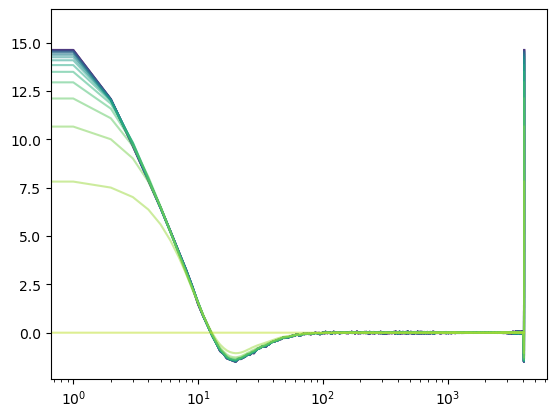

In [41]:
cmap = plt.get_cmap("viridis")
i=0
for S_test in Ss:
    plt.plot(np.abs(S_test)-np.abs(S), alpha=0.5,c=cmap(i/20))
    i+=1
plt.xscale("log")

In [18]:
f1_opt, f2_opt, J_values = an.optimize_filters(S_torch, H_unit_torch, w_torch, t_torch, r_torch, nps_torch,
                                                       signal_amp_torch, ratio_distribution_torch, N_sigma=N_sigma,
                                               f1_init = f1_t, f2_init = f2_t,n_trials=500, verbose=True,pulse_center_ratio=0.1)

Step 0: J = 0.188421
Step 10: J = 0.188281
Step 20: J = 0.187946
Step 30: J = 0.187890
Step 40: J = 0.187772
Step 50: J = 0.187772
Step 60: J = 0.187773
Step 70: J = 0.187734
Step 80: J = 0.187741
Step 90: J = 0.187750
Step 100: J = 0.187665
Step 110: J = 0.187682
Step 120: J = 0.187671
Step 130: J = 0.187638
Step 140: J = 0.187643
Step 150: J = 0.187647
Step 160: J = 0.187569
Step 170: J = 0.187592
Step 180: J = 0.187557
Step 190: J = 0.187574
Step 200: J = 0.187540
Step 210: J = 0.187534
Step 220: J = 0.187485
Step 230: J = 0.187441
Step 240: J = 0.187449
Step 250: J = 0.187434
Step 260: J = 0.187373
Step 270: J = 0.187363
Step 280: J = 0.187370
Step 290: J = 0.187304
Step 300: J = 0.187329
Step 310: J = 0.187286
Step 320: J = 0.187316
Step 330: J = 0.187274
Step 340: J = 0.187212
Step 350: J = 0.187257
Step 360: J = 0.187278
Step 370: J = 0.187154
Step 380: J = 0.187185
Step 390: J = 0.187154
Step 400: J = 0.187147
Step 410: J = 0.187061
Step 420: J = 0.187097
Step 430: J = 0.187227

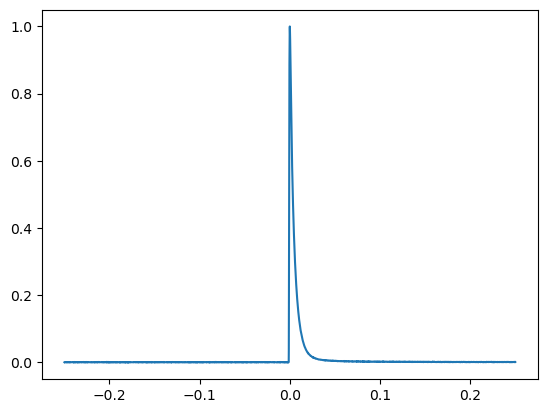

In [8]:
meas_name = "000813_20230628T161508"
from scipy.optimize import curve_fit
channel = 5
meanpulse = np.fromfile(ds.find_file(f"{meas_name}_{channel:03}_???.bin_edmean.bin",
                                     specific_subdir="RUN9_pulse_injected_new/"))
t = np.arange(-len(meanpulse) // 2, len(meanpulse) // 2) * 1e-4
p0 = [1, t[np.argmax(meanpulse)], -1000, -1339.1, -237.0, -100, -1000.0]
fit_fct_pole = lambda x, *params: sim.apply_bessel_to_pulse(x, sim.pulse_pole_zero(x, *params), fc=2500, order=6,
                                                            fs=1e4)
popt, pcov = curve_fit(fit_fct_pole, t, meanpulse, p0=p0,
                       bounds=([0, -0.5, -5000, -5000, -5000, -5000, -5000], [10, 0.5, 0, 0, 0, 0, 0]))
fitted_pulse_function = lambda t: fit_fct_pole(t*1e-4, *popt)
plt.plot(t, meanpulse, label="Meanpulse")

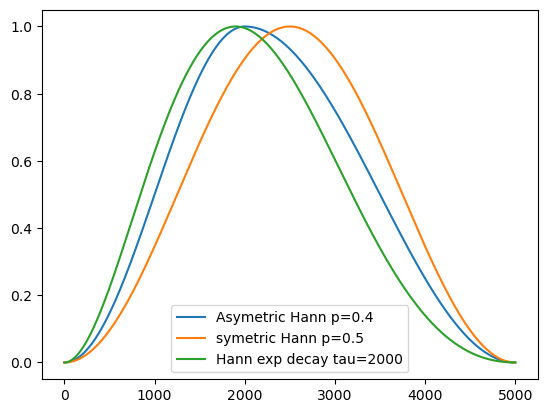

In [21]:

def hann_exp_decay(N, tau, normalize=True):
    """
    Hann window multiplied by an exponential decay.

    Parameters
    ----------
    N : int
        Window length
    tau : float
        Exponential decay constant (in samples)
    normalize : bool
        Normalize max to 1

    Returns
    -------
    w : ndarray
        Window of length N
    """
    n = np.arange(N)

    hann = 0.5 * (1 - np.cos(2 * np.pi * n / (N - 1)))
    exp_decay = np.exp(-n / tau)

    w = hann * exp_decay

    if normalize:
        w /= w.max()

    return w

#plt.loglog(np.abs(np.fft.rfft(asymmetric_hann(5000,0.4))), label="Asymetric Hann p=0.3")
#plt.loglog(np.abs(np.fft.rfft(asymmetric_hann(5000,0.5))), label="symetric Hann p=0.5")
plt.plot(asymmetric_hann(5000,0.4),label="Asymetric Hann p=0.4")
plt.plot(asymmetric_hann(5000,0.5),label="symetric Hann p=0.5")
plt.plot(hann_exp_decay(5000,2000),label="Hann exp decay tau=2000")
plt.legend()